In [1]:
!pip install ultralytics -q

import os
import cv2
import yaml
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from collections import Counter

print("Libraries loaded!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.6 MB/s eta 0:00:00
Libraries loaded!


In [2]:
BASE_PATH   = '/kaggle/input/datasets/sakshamjn/vehicle-detection-8-classes-object-detection'
IMG_DIR     = f'{BASE_PATH}/train/images'
LABEL_DIR   = f'{BASE_PATH}/train/labels'

img_files   = [f for f in os.listdir(IMG_DIR)   if f.endswith('.jpg')]
label_files = [f for f in os.listdir(LABEL_DIR) if f.endswith('.txt')]

print(f"Total gambar : {len(img_files)}")
print(f"Total label  : {len(label_files)}")
print(f"\nContoh gambar : {img_files[0]}")
print(f"Contoh label  : {label_files[0]}")

Total gambar : 8218
Total label  : 8219

Contoh gambar : Highway_143_2020-07-30_jpg.rf.a7076f71b722e151bc3533a818aea182.jpg
Contoh label  : ulu1386_jpg.rf.a5750e969785c5d69b5980d51e7f0b6b.txt


In [3]:
# Baca 1 file label untuk lihat formatnya
sample_label_path = os.path.join(LABEL_DIR, label_files[0])

print(f"File: {label_files[0]}")
print(f"Isi (1 baris = 1 objek):")
print("-" * 50)
with open(sample_label_path, 'r') as f:
    for line in f.readlines():
        print(line.strip())

print("\nFormat: class_id  cx  cy  w  h  (semua ternormalisasi 0-1)")

File: ulu1386_jpg.rf.a5750e969785c5d69b5980d51e7f0b6b.txt
Isi (1 baris = 1 objek):
--------------------------------------------------
2 0.532452 0.531250 0.098558 0.240385
2 0.719952 0.194712 0.069712 0.096154
4 0.481971 0.155048 0.026442 0.074519

Format: class_id  cx  cy  w  h  (semua ternormalisasi 0-1)


Distribusi kelas:
  [0] auto                     : 819
  [1] bus                      : 1319
  [2] car                      : 11425
  [3] light_motor_vehicle      : 969
  [4] motorcycle               : 7285
  [5] multi-axle               : 1147
  [6] tractor                  : 171
  [7] truck                    : 2963


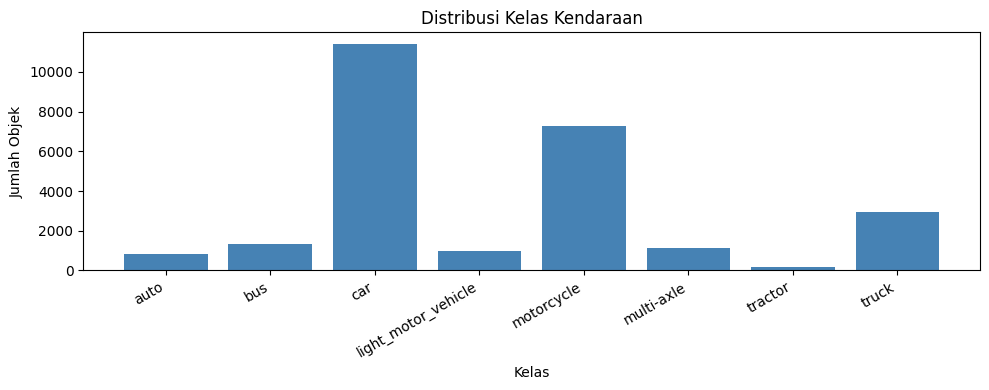

In [4]:
# Cek nama kelas dari labels.npy jika ada, atau definisi manual
CLASSES = [
    'auto', 'bus', 'car','light_motor_vehicle', 'motorcycle', 'multi-axle', 'tractor', 'truck'
]

# Hitung distribusi kelas dari semua file label
all_class_ids = []
for label_file in label_files:
    label_path = os.path.join(LABEL_DIR, label_file)
    try:
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    all_class_ids.append(int(parts[0]))
    except:
        pass

class_counts = Counter(all_class_ids)
print("Distribusi kelas:")
for cls_id, count in sorted(class_counts.items()):
    name = CLASSES[cls_id] if cls_id < len(CLASSES) else f"class_{cls_id}"
    print(f"  [{cls_id}] {name:<25}: {count}")

# Visualisasi
names  = [CLASSES[i] if i < len(CLASSES) else f"class_{i}"
          for i in sorted(class_counts.keys())]
counts = [class_counts[i] for i in sorted(class_counts.keys())]

plt.figure(figsize=(10, 4))
plt.bar(names, counts, color='steelblue')
plt.title('Distribusi Kelas Kendaraan')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Objek')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

/tmp/ipykernel_23/3447362047.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', len(classes))


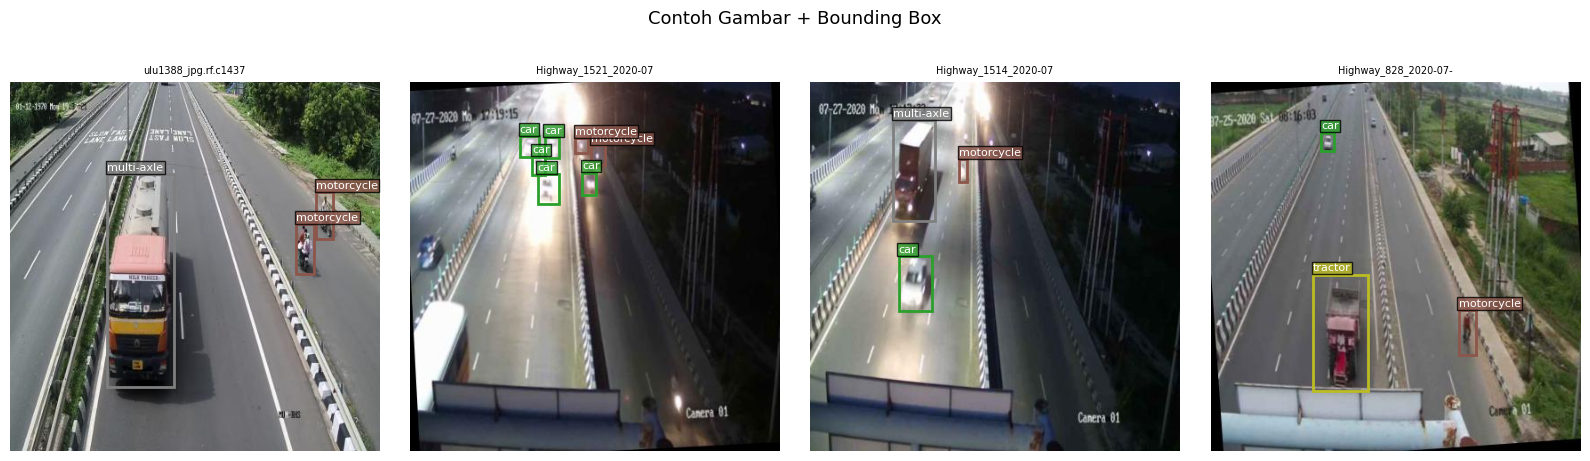

In [ ]:
def yolo_to_pixel(cx, cy, w, h, img_w, img_h):
    x1 = int((cx - w / 2) * img_w)
    y1 = int((cy - h / 2) * img_h)
    x2 = int((cx + w / 2) * img_w)
    y2 = int((cy + h / 2) * img_h)
    return x1, y1, x2, y2

def show_samples(img_dir, label_dir, classes, n=4):
    pairs = []
    for img_file in os.listdir(img_dir):
        if not img_file.endswith('.jpg'):
            continue
        label_file = img_file.replace('.jpg', '.txt')
        if os.path.exists(os.path.join(label_dir, label_file)):
            pairs.append((img_file, label_file))

    random.shuffle(pairs)
    pairs = pairs[:n]

    colors = plt.cm.get_cmap('tab10', len(classes))
    fig, axes = plt.subplots(1, n, figsize=(16, 5))

    for ax, (img_file, label_file) in zip(axes, pairs):
        img     = cv2.imread(os.path.join(img_dir, img_file))
        img     = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        ax.imshow(img)

        with open(os.path.join(label_dir, label_file), 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls_id         = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                x1, y1, x2, y2 = yolo_to_pixel(cx, cy, bw, bh, w, h)
                label           = classes[cls_id] if cls_id < len(classes) else str(cls_id)
                color           = colors(cls_id)[:3]

                rect = patches.Rectangle(
                    (x1, y1), x2 - x1, y2 - y1,
                    linewidth=2, edgecolor=color, facecolor='none'
                )
                ax.add_patch(rect)
                ax.text(x1, y1 - 4, label, fontsize=8,
                        color='white',
                        bbox=dict(fc=color, alpha=0.8, pad=1))

        ax.axis('off')
        ax.set_title(img_file[:20], fontsize=7)

    plt.suptitle('Contoh Gambar + Bounding Box', fontsize=13)
    plt.tight_layout()
    plt.show()

show_samples(IMG_DIR, LABEL_DIR, CLASSES)

In [ ]:
# Dataset sudah dalam format YOLO, tinggal buat file YAML konfigurasi
yaml_config = {
    'path' : f'{BASE_PATH}/train',
    'train': 'images',
    'val'  : 'images',   
    'nc'   : len(CLASSES),
    'names': CLASSES
}

yaml_path = '/kaggle/working/vehicle_data.yaml'
with open(yaml_path, 'w') as f:
    yaml.dump(yaml_config, f, default_flow_style=False)

print("File YAML berhasil dibuat:")
with open(yaml_path) as f:
    print(f.read())

File YAML berhasil dibuat:
names:
- auto
- bus
- car
- light_motor_vehicle
- motorcycle
- multi-axle
- tractor
- truck
nc: 8
path: /kaggle/input/datasets/sakshamjn/vehicle-detection-8-classes-object-detection/train
train: images
val: images



In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')  
print("Model loaded!")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Model loaded!


In [ ]:
results = model.train(
    data    = yaml_path,
    epochs  = 10,
    imgsz   = 640,
    batch   = 16,   
    name    = 'vehicle_yolov8',
    project = '/kaggle/working/runs',
    device  = 0
)

print("Training selesai!")

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/vehicle_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vehicle_yolov8, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, p

In [9]:
metrics = model.val()

print("=== Hasil Evaluasi ===")
print(f"mAP@0.5      : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.4f}")
print(f"Precision    : {metrics.box.mp:.4f}")
print(f"Recall       : {metrics.box.mr:.4f}")

Ultralytics 8.4.33 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,007,208 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 43.8±57.2 MB/s, size: 53.3 KB)
val: Scanning /kaggle/input/datasets/sakshamjn/vehicle-detection-8-classes-object-detection/train/labels... 8218 images, 18 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8218/8218 385.0it/s 21.3s
val: /kaggle/input/datasets/sakshamjn/vehicle-detection-8-classes-object-detection/train/images/highway_2784_2020-08-26.jpg: 1 duplicate labels removed
val: /kaggle/input/datasets/sakshamjn/vehicle-detection-8-classes-object-detection/train/images/highway_3297_2020-08-26.jpg: 1 duplicate labels removed
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/sakshamjn/vehicle-detection-8-classes-object-detection/train is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51

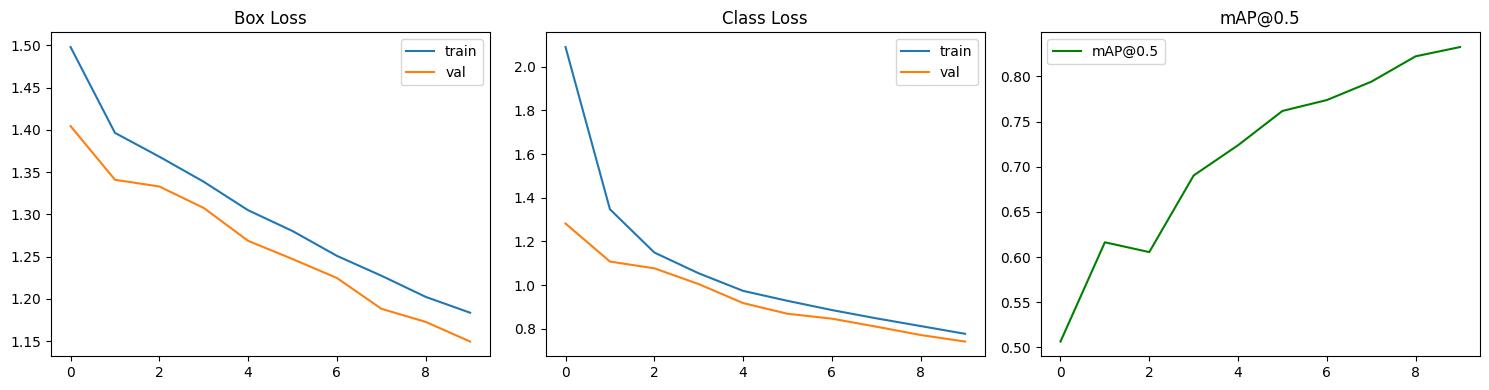

In [10]:
import glob
import pandas as pd

results_csv = glob.glob('/kaggle/working/runs/vehicle_yolov8/results.csv')
if results_csv:
    df = pd.read_csv(results_csv[0])
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(df['train/box_loss'], label='train')
    axes[0].plot(df['val/box_loss'],   label='val')
    axes[0].set_title('Box Loss')
    axes[0].legend()

    axes[1].plot(df['train/cls_loss'], label='train')
    axes[1].plot(df['val/cls_loss'],   label='val')
    axes[1].set_title('Class Loss')
    axes[1].legend()

    axes[2].plot(df['metrics/mAP50(B)'], label='mAP@0.5', color='green')
    axes[2].set_title('mAP@0.5')
    axes[2].legend()

    plt.tight_layout()
    plt.show()

In [11]:
best_model = YOLO('/kaggle/working/runs/vehicle_yolov8/weights/best.pt')
print("Best model loaded!")

Best model loaded!


/tmp/ipykernel_23/22748565.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap  = plt.cm.get_cmap('tab10', len(CLASSES))


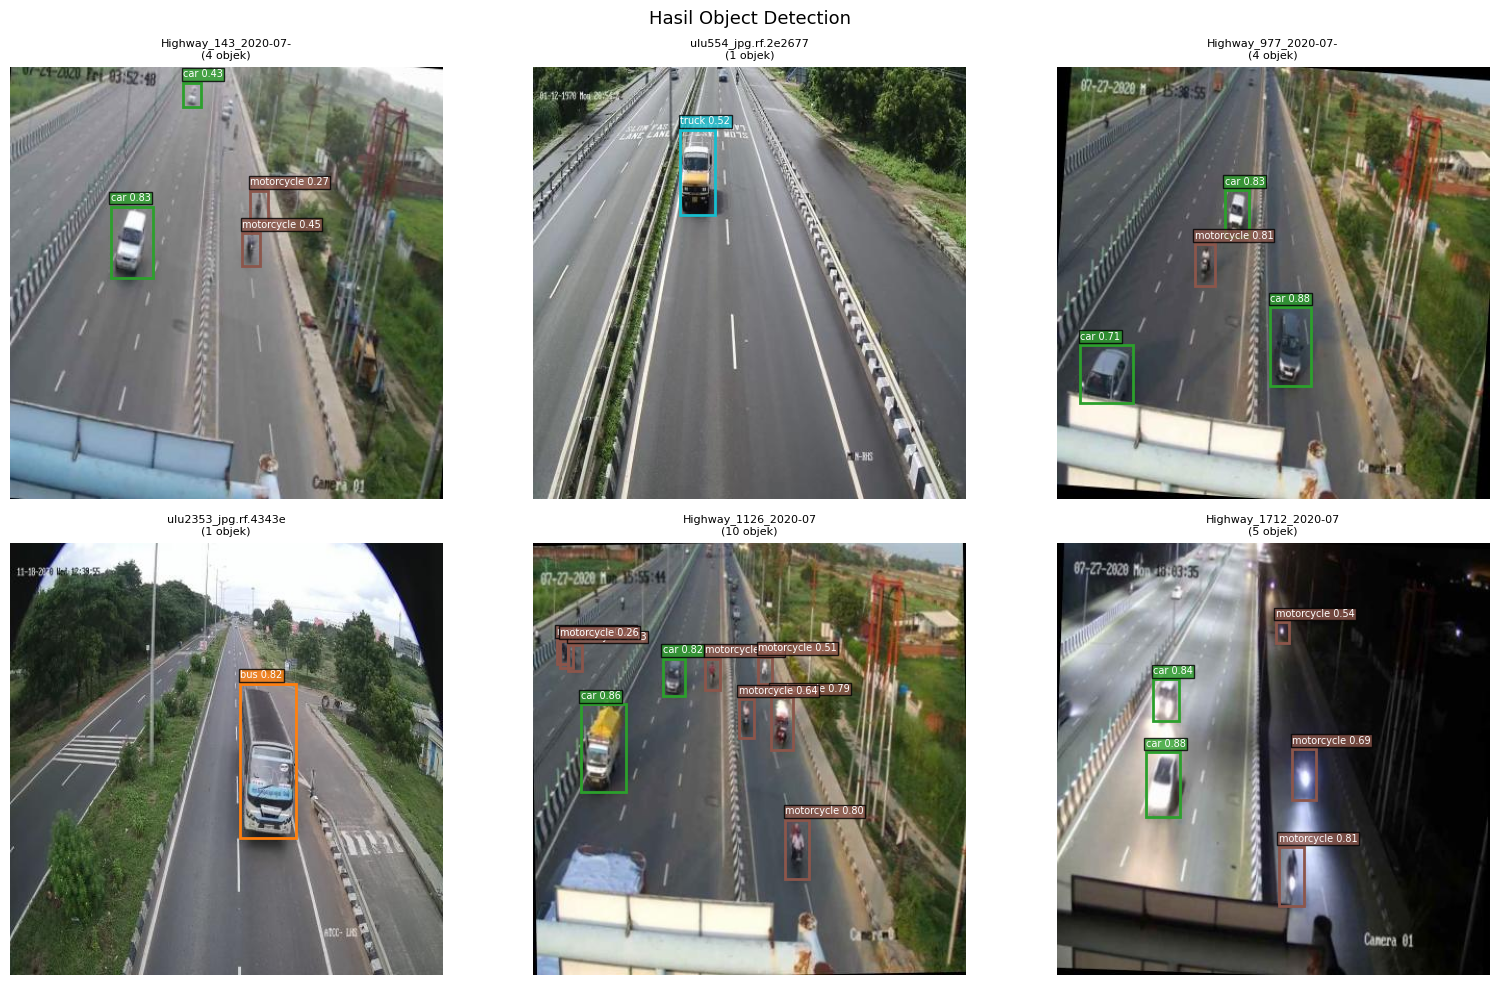

In [12]:
val_images = list(Path(IMG_DIR).glob('*.jpg'))[:6]

def predict_and_show(model, image_paths, conf=0.25):
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes  = axes.flatten()
    cmap  = plt.cm.get_cmap('tab10', len(CLASSES))

    for idx, img_path in enumerate(image_paths):
        result = model.predict(str(img_path), conf=conf, verbose=False)[0]
        img    = cv2.imread(str(img_path))
        img    = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[idx].imshow(img)

        for box in result.boxes:
            cls_id     = int(box.cls[0])
            label      = CLASSES[cls_id] if cls_id < len(CLASSES) else str(cls_id)
            confidence = float(box.conf[0])
            x1,y1,x2,y2 = [int(v) for v in box.xyxy[0]]
            color      = cmap(cls_id)[:3]

            rect = patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                linewidth=2, edgecolor=color, facecolor='none'
            )
            axes[idx].add_patch(rect)
            axes[idx].text(
                x1, y1-5, f"{label} {confidence:.2f}",
                fontsize=7, color='white',
                bbox=dict(fc=color, alpha=0.8, pad=1)
            )

        axes[idx].axis('off')
        axes[idx].set_title(
            f"{img_path.name[:20]}\n({len(result.boxes)} objek)", fontsize=8
        )

    plt.suptitle('Hasil Object Detection', fontsize=13)
    plt.tight_layout()
    plt.show()

predict_and_show(best_model, val_images)

In [13]:
def format_multiline_output(model, img_path, conf=0.25):
    result = model.predict(str(img_path), conf=conf, verbose=False)[0]

    print(f"Image : {Path(img_path).name}")
    print("-" * 58)
    print(f"{'No':<4} {'Label':<22} {'Conf':<6} {'BBox [x1, y1, x2, y2]'}")
    print("-" * 58)

    for i, box in enumerate(result.boxes, 1):
        cls_id       = int(box.cls[0])
        label        = CLASSES[cls_id] if cls_id < len(CLASSES) else str(cls_id)
        confidence   = float(box.conf[0])
        x1,y1,x2,y2 = [int(v) for v in box.xyxy[0]]

        # ← output multiline: 1 baris per objek
        print(f"{i:<4} {label:<22} {confidence:.2f}   [{x1:>4}, {y1:>4}, {x2:>4}, {y2:>4}]")

    print("-" * 58)
    print(f"Total : {len(result.boxes)} objek terdeteksi\n")

for img_path in val_images[:3]:
    format_multiline_output(best_model, img_path)

Image : Highway_143_2020-07-30_jpg.rf.a7076f71b722e151bc3533a818aea182.jpg
----------------------------------------------------------
No   Label                  Conf   BBox [x1, y1, x2, y2]
----------------------------------------------------------
1    car                    0.83   [  90,  125,  128,  189]
2    motorcycle             0.45   [ 208,  149,  224,  178]
3    car                    0.43   [ 155,   14,  171,   36]
4    motorcycle             0.27   [ 215,  111,  231,  139]
----------------------------------------------------------
Total : 4 objek terdeteksi

Image : ulu554_jpg.rf.2e267781b53958af49b1e9ab5f264d9a.jpg
----------------------------------------------------------
No   Label                  Conf   BBox [x1, y1, x2, y2]
----------------------------------------------------------
1    truck                  0.52   [ 141,   60,  174,  142]
----------------------------------------------------------
Total : 1 objek terdeteksi

Image : Highway_977_2020-07-30_jpg.rf.3661